## Домашнее задание №4 «Задачи на формулу Байеса и условную вероятность»
### Задачи на формулу Байеса и условную вероятность

**Цель**: Вспомнить и закрепить понятие условной вероятности и формулы Байеса.

**Студент**: Сизиков Константин.

**1. Путешествие в страну Х**
**Задача**: Вы отправляетесь в страну X, которая славится своими мистическими приключениями. Вам предстоит пройти через две опасные локации: лес и горы.

В лесу есть две возможные тропы - тропа A и тропа B. Вы можете выбрать одну из них случайным образом. Вероятность выбрать тропу A равна 0.4, а тропу B - 0.6. После выбора тропы вы перемещаетесь в горы. Вероятность успешно пройти горы, если вы выбрали тропу A, составляет 0.3. Если же вы выбрали тропу B, вероятность успешного прохождения гор увеличивается до 0.7.

**Вопрос**: Какова вероятность успешно пройти оба этапа путешествия (попасть в страну X) и как она зависит от выбора тропы в лесу?

**2. Лабиринт сокровищ**
**Задача**: Вы оказались в лабиринте, который славится своими сокровищами. Чтобы добраться до сокровищ, вам нужно пройти через три замка: замок A, замок B и замок C. Каждый замок защищен различными ловушками и подходы к каждому из них различны.

Замок A: Первый замок защищен огненными ловушками. Вероятность успешно пройти замок A составляет 0.6.
Замок B: После успешного прохождения замка A, вы переходите к замку B. Замок B защищен сложными головоломками. Если вы успешно прошли замок A, вероятность успешно пройти замок B составляет 0.4. Однако, если вы не смогли пройти замок A, то вероятность успешно пройти замок B уменьшается до 0.2.
Замок C: После прохождения замка B, вам предстоит столкнуться с последней преградой - замком C. Замок C охраняется могучим воином. Если вы успешно прошли замок B, вероятность успешно пройти замок C составляет 0.7. Однако, если вы не смогли пройти замок B, то вероятность успешно пройти замок C уменьшается до 0.3.

**Вопрос**: Какова вероятность добраться до сокровища (пройти все три замка) и как она зависит от вашего успешного прохождения предыдущих замков?

**3. Заболевание и результаты тестирования**
**Задача**: Представим, что у определенной популяции есть редкое заболевание, которое встречается у 1% людей. Существует медицинский тест для определения этого заболевания. Тест имеет высокую точность: вероятность правильно определить наличие заболевания у больного составляет 0.95, а вероятность правильно определить отсутствие заболевания у здорового составляет 0.90.

**Вопрос**: Если у человека положительный тест на заболевание, какова вероятность того, что он действительно болен этим заболеванием?

**4. Студенты и предметы**
**Задача**: В университете есть два курса по математике: Алгебра и Анализ. Студенты изучают оба предмета, и 70% студентов посещают курс Алгебры, а 30% студентов посещают курс Анализа. Вероятность того, что студент с курса Алгебры сдаст экзамен, составляет 80%, а вероятность того, что студент с курса Анализа сдаст экзамен, составляет 70%.

**Вопрос**: Если студент сдал экзамен по математике. Какова вероятность того, что он изучал курс Алгебры?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
N = 1_000_000  # число симуляций для проверки Монте-Карло

pd.set_option("display.float_format", "{:.4f}".format)

In [ ]:
def total_probability(priors, likelihoods):
    # Формула полной вероятности: P(A) = sum P(H_i) * P(A|H_i)
    priors, likelihoods = np.asarray(priors), np.asarray(likelihoods)
    return float(np.sum(priors * likelihoods))


def bayes(priors, likelihoods):
    # Апостериорные вероятности гипотез P(H_i|A) по формуле Байеса
    priors, likelihoods = np.asarray(priors), np.asarray(likelihoods)
    joint = priors * likelihoods
    return joint / joint.sum()

## Задача 1. «Путешествие в страну X»

**Дано:**
- $P(A) = 0.4$, $P(B) = 0.6$ — выбор тропы в лесу (полная группа гипотез);
- $P(S \mid A) = 0.3$, $P(S \mid B) = 0.7$, где $S$ — успешное прохождение гор.

Лес проходится в любом случае (нужно лишь выбрать тропу), поэтому успех путешествия = успешное прохождение гор $S$.

**Решение.** По правилу умножения вероятности совместных событий:

$$P(A \cap S) = 0.4 \cdot 0.3 = 0.12, \qquad P(B \cap S) = 0.6 \cdot 0.7 = 0.42.$$

По формуле полной вероятности:

$$P(S) = P(A)P(S \mid A) + P(B)P(S \mid B) = 0.12 + 0.42 = 0.54.$$

Зависимость от выбора тропы дополнительно оценим по формуле Байеса — какую тропу, скорее всего, выбрал путешественник, добравшийся до страны X:

$$P(A \mid S) = \frac{0.12}{0.54} \approx 0.222, \qquad P(B \mid S) = \frac{0.42}{0.54} \approx 0.778.$$

In [3]:
p_path = {"A": 0.4, "B": 0.6}
p_success_given = {"A": 0.3, "B": 0.7}

priors = list(p_path.values())
lik = list(p_success_given.values())

p_success = total_probability(priors, lik)
posterior = bayes(priors, lik)

task1 = pd.DataFrame({
    "P(тропа)": priors,
    "P(S | тропа)": lik,
    "P(тропа ∩ S)": np.array(priors) * np.array(lik),
    "P(тропа | S)": posterior,
}, index=["Тропа A", "Тропа B"])
display(task1)
print(f"P(успешно пройти оба этапа) = {p_success:.4f}")
print(f"Если сознательно выбрать тропу A: {p_success_given['A']:.2f}, тропу B: {p_success_given['B']:.2f}")
print(f"Тропа B выгоднее в {p_success_given['B'] / p_success_given['A']:.2f} раза")

,P(тропа),P(S | тропа),P(тропа ∩ S),P(тропа | S)
Тропа A,0.4000,0.3000,0.1200,0.2222
Тропа B,0.6000,0.7000,0.4200,0.7778


P(успешно пройти оба этапа) = 0.5400
Если сознательно выбрать тропу A: 0.30, тропу B: 0.70
Тропа B выгоднее в 2.33 раза


In [4]:
# Проверка Монте-Карло
path_is_A = rng.random(N) < p_path["A"]
p_s = np.where(path_is_A, p_success_given["A"], p_success_given["B"])
success = rng.random(N) < p_s

print(f"P(S)     ≈ {success.mean():.4f}  (аналитически {p_success:.4f})")
print(f"P(A | S) ≈ {path_is_A[success].mean():.4f}  (аналитически {posterior[0]:.4f})")

P(S)     ≈ 0.5406  (аналитически 0.5400)
P(A | S) ≈ 0.2220  (аналитически 0.2222)


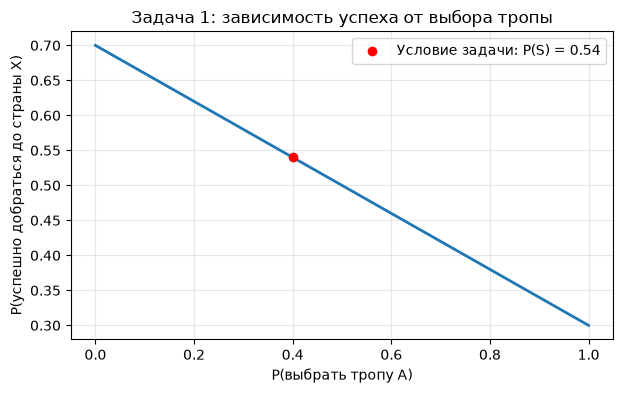

In [5]:
# Как итоговая вероятность зависит от вероятности выбора тропы A
p_A_grid = np.linspace(0, 1, 101)
p_S_grid = p_A_grid * p_success_given["A"] + (1 - p_A_grid) * p_success_given["B"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p_A_grid, p_S_grid, lw=2)
ax.scatter([p_path["A"]], [p_success], color="red", zorder=3, label=f"Условие задачи: P(S) = {p_success:.2f}")
ax.set_xlabel("P(выбрать тропу A)")
ax.set_ylabel("P(успешно добраться до страны X)")
ax.set_title("Задача 1: зависимость успеха от выбора тропы")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Ответ к задаче 1.** Вероятность успешно пройти оба этапа при случайном выборе тропы $P(S) = 0.54$.
Зависимость от тропы сильная: при тропе A шанс всего 0.3, при тропе B — 0.7 (в 2.33 раза выше).
Итоговая вероятность линейно убывает с ростом вероятности выбрать тропу A: от 0.7 (всегда B) до 0.3 (всегда A).
Среди успешно добравшихся путешественников ≈77.8% шли по тропе B и только ≈22.2% — по тропе A.

## Задача 2. «Лабиринт сокровищ»

**Дано** (события $A, B, C$ — успешное прохождение соответствующих замков):
- $P(A) = 0.6$;
- $P(B \mid A) = 0.4$, $P(B \mid \bar A) = 0.2$;
- $P(C \mid B) = 0.7$, $P(C \mid \bar B) = 0.3$.

Получение сокровища — это событие $T = A \cap B \cap C$ (пройдены все три замка).

**Допущение.** Предполагаем, что вероятность прохождения замка C зависит только от результата в замке B,
то есть C условно независимо от A при известном B (цепь Маркова): $P(C \mid A \cap B) = P(C \mid B)$.
Для правила умножения нужна именно $P(C \mid A \cap B)$, а в условии дана $P(C \mid B)$; без этого допущения данных
недостаточно для однозначного вычисления $P(A \cap B \cap C)$. Например, при $P(C \mid A \cap B) = 0.8$ и
$P(C \mid \bar A \cap B) = 0.4$ по-прежнему $P(C \mid B) = (0.24 \cdot 0.8 + 0.08 \cdot 0.4)/0.32 = 0.7$,
но $P(A \cap B \cap C) = 0.24 \cdot 0.8 = 0.192$.

**Решение.** При принятом допущении вероятность пройти все три замка по правилу умножения:

$$P(A \cap B \cap C) = P(A)\,P(B \mid A)\,P(C \mid B) = 0.6 \cdot 0.4 \cdot 0.7 = 0.168.$$

Для анализа зависимости также найдём безусловные вероятности по формуле полной вероятности:

$$P(B) = 0.6 \cdot 0.4 + 0.4 \cdot 0.2 = 0.32,$$
$$P(C) = P(B)\,P(C \mid B) + P(\bar B)\,P(C \mid \bar B) = 0.32 \cdot 0.7 + 0.68 \cdot 0.3 = 0.428.$$

In [6]:
pA = 0.6
pB_given = {True: 0.4, False: 0.2}   # P(B | A), P(B | not A)
pC_given = {True: 0.7, False: 0.3}   # P(C | B), P(C | not B)

rows = []
for a in (True, False):
    for b in (True, False):
        for c in (True, False):
            p = (pA if a else 1 - pA) \
                * (pB_given[a] if b else 1 - pB_given[a]) \
                * (pC_given[b] if c else 1 - pC_given[b])
            rows.append({"A": "✓" if a else "✗", "B": "✓" if b else "✗",
                         "C": "✓" if c else "✗", "P(исход)": p})

outcomes = pd.DataFrame(rows).sort_values("P(исход)", ascending=False).reset_index(drop=True)
display(outcomes)
print(f"Сумма вероятностей всех исходов: {outcomes['P(исход)'].sum():.4f}")

,A,B,C,P(исход)
0,✓,✗,✗,0.2520
1,✗,✗,✗,0.2240
2,✓,✓,✓,0.1680
3,✓,✗,✓,0.1080
4,✗,✗,✓,0.0960
5,✓,✓,✗,0.0720
6,✗,✓,✓,0.0560
7,✗,✓,✗,0.0240


Сумма вероятностей всех исходов: 1.0000


In [7]:
p_all = pA * pB_given[True] * pC_given[True]
p_B = total_probability([pA, 1 - pA], [pB_given[True], pB_given[False]])
p_C = total_probability([p_B, 1 - p_B], [pC_given[True], pC_given[False]])

print(f"P(A ∩ B ∩ C) — пройти все три замка = {p_all:.4f}")
print(f"P(B) = {p_B:.4f},  P(C) = {p_C:.4f}")
print()

# Вероятность получить сокровище T = A∩B∩C при известном результате предыдущих замков
p_T_cond = {
    "P(T)":       p_all,
    "P(T | A)":   pB_given[True] * pC_given[True],
    "P(T | ¬A)":  0.0,   # A не пройден — пройти все три замка уже невозможно
    "P(T | A∩B)": pC_given[True],
    "P(T | ¬B)":  0.0,   # B не пройден — пройти все три замка уже невозможно
}
print("Вероятность получить сокровище в зависимости от уже достигнутого:")
for k, v in p_T_cond.items():
    print(f"  {k:<11} = {v:.4f}")
print()

# Вероятности прохождения следующего замка (это НЕ вероятности получить сокровище)
p_next = {
    "P(B | A)":  pB_given[True],
    "P(B | ¬A)": pB_given[False],
    "P(C | B)":  pC_given[True],
    "P(C | ¬B)": pC_given[False],
}
print("Вероятности прохождения следующего замка:")
for k, v in p_next.items():
    print(f"  {k:<9} = {v:.4f}")
print()

# Обратная задача (Байес): что можно сказать о предыдущих замках, если замок C пройден?
# (Если известно получение сокровища T, то P(B | T) = P(A∩B | T) = 1.)
p_B_given_C = p_B * pC_given[True] / p_C
p_AB_given_C = p_all / p_C
print(f"Байес: P(B | C) = {p_B_given_C:.4f},  P(A∩B | C) = {p_AB_given_C:.4f}")

P(A ∩ B ∩ C) — пройти все три замка = 0.1680
P(B) = 0.3200,  P(C) = 0.4280

Вероятность получить сокровище в зависимости от уже достигнутого:
  P(T)        = 0.1680
  P(T | A)    = 0.2800
  P(T | ¬A)   = 0.0000
  P(T | A∩B)  = 0.7000
  P(T | ¬B)   = 0.0000

Вероятности прохождения следующего замка:
  P(B | A)  = 0.4000
  P(B | ¬A) = 0.2000
  P(C | B)  = 0.7000
  P(C | ¬B) = 0.3000

Байес: P(B | C) = 0.5234,  P(A∩B | C) = 0.3925


In [8]:
# Проверка Монте-Карло
a = rng.random(N) < pA
b = rng.random(N) < np.where(a, pB_given[True], pB_given[False])
c = rng.random(N) < np.where(b, pC_given[True], pC_given[False])

print(f"P(A∩B∩C) ≈ {(a & b & c).mean():.4f}  (аналитически {p_all:.4f})")
print(f"P(B)     ≈ {b.mean():.4f}  (аналитически {p_B:.4f})")
print(f"P(C)     ≈ {c.mean():.4f}  (аналитически {p_C:.4f})")
print(f"P(B | C) ≈ {b[c].mean():.4f}  (аналитически {p_B_given_C:.4f})")

P(A∩B∩C) ≈ 0.1682  (аналитически 0.1680)
P(B)     ≈ 0.3201  (аналитически 0.3200)
P(C)     ≈ 0.4277  (аналитически 0.4280)
P(B | C) ≈ 0.5239  (аналитически 0.5234)


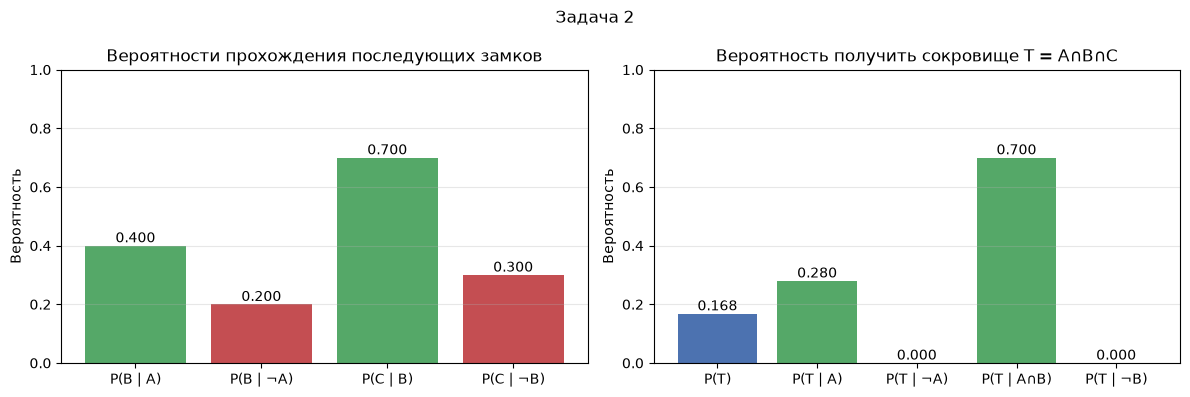

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
panels = [
    (p_next, ["#55a868", "#c44e52", "#55a868", "#c44e52"], "Вероятности прохождения последующих замков"),
    (p_T_cond, ["#4c72b0", "#55a868", "#c44e52", "#55a868", "#c44e52"], "Вероятность получить сокровище T = A∩B∩C"),
]
for ax, (data, colors, title) in zip(axes, panels):
    bars = ax.bar(list(data.keys()), list(data.values()), color=colors)
    ax.bar_label(bars, fmt="%.3f")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Вероятность")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Задача 2")
plt.tight_layout()
plt.show()

**Ответ к задаче 2.** При допущении, что C условно независимо от A при известном B, вероятность получить сокровище
$P(T) = P(A \cap B \cap C) = 0.6 \cdot 0.4 \cdot 0.7 = 0.168$ (≈16.8%).

Зависимость от предыдущих этапов:
- вероятность получить сокровище: с начала — 0.168, после успешного A — 0.28, после успешных A и B — 0.7; при провале A или B получить сокровище уже невозможно ($P(T \mid \bar A) = P(T \mid \bar B) = 0$);
- успех в замке A вдвое повышает шанс пройти замок B (0.4 против 0.2);
- успех в замке B повышает шанс пройти замок C с 0.3 до 0.7 (в 2.33 раза); результат замка A влияет на C только опосредованно, через B.

Безусловно замок B проходят с вероятностью 0.32, замок C — 0.428 (это не вероятность получить сокровище: C можно пройти и после провалов).
Если известно, что замок C пройден, то по Байесу с вероятностью ≈0.523 был пройден замок B и ≈0.393 — пройдены и A, и B.

## Задача 3. «Заболевание и результаты тестирования»

**Дано:** $D$ — человек болен, $+$ — положительный тест.
- $P(D) = 0.01$, $P(\bar D) = 0.99$;
- чувствительность $P(+ \mid D) = 0.95$;
- специфичность $P(- \mid \bar D) = 0.90 \Rightarrow$ ложноположительный результат $P(+ \mid \bar D) = 0.10$.

**Решение.** Полная вероятность положительного теста:

$$P(+) = 0.01 \cdot 0.95 + 0.99 \cdot 0.10 = 0.0095 + 0.099 = 0.1085.$$

По формуле Байеса:

$$P(D \mid +) = \frac{P(D)\,P(+ \mid D)}{P(+)} = \frac{0.0095}{0.1085} \approx 0.0876.$$

In [10]:
p_D = 0.01
sens = 0.95      # P(+ | D)
spec = 0.90      # P(- | not D)

p_pos = total_probability([p_D, 1 - p_D], [sens, 1 - spec])
p_D_given_pos = bayes([p_D, 1 - p_D], [sens, 1 - spec])[0]
p_notD_given_neg = (1 - p_D) * spec / (1 - p_pos)

print(f"P(+)       = {p_pos:.4f}")
print(f"P(D | +)   = {p_D_given_pos:.4f}  ({p_D_given_pos:.2%})")
print(f"P(¬D | -)  = {p_notD_given_neg:.5f}  — в данной модели вероятность отсутствия заболевания при отрицательном тесте ≈ {p_notD_given_neg:.3%}")

# Наглядно на 10 000 человек
n = 10_000
sick, healthy = n * p_D, n * (1 - p_D)
tp, fp = sick * sens, healthy * (1 - spec)
display(pd.DataFrame(
    {"Тест +": [tp, fp], "Тест −": [sick - tp, healthy - fp]},
    index=["Больны", "Здоровы"]).round().astype(int))
print(f"Из {tp + fp:.0f} положительных тестов больны лишь {tp:.0f} (ожидаемые количества в модели)")

P(+)       = 0.1085
P(D | +)   = 0.0876  (8.76%)
P(¬D | -)  = 0.99944  — в данной модели вероятность отсутствия заболевания при отрицательном тесте ≈ 99.944%


,Тест +,Тест −
Больны,95,5
Здоровы,990,8910


Из 1085 положительных тестов больны лишь 95 (ожидаемые количества в модели)


In [11]:
# Проверка Монте-Карло
is_sick = rng.random(N) < p_D
positive = rng.random(N) < np.where(is_sick, sens, 1 - spec)
print(f"P(D | +) ≈ {is_sick[positive].mean():.4f}  (аналитически {p_D_given_pos:.4f})")

# Повторный положительный тест. Допущение: результаты тестов условно независимы при фиксированном статусе
# заболевания, чувствительность и специфичность обоих тестов одинаковы. Апостериор становится новым априором.
p_after_2 = bayes([p_D_given_pos, 1 - p_D_given_pos], [sens, 1 - spec])[0]
print(f"P(D | два положительных теста) = {p_after_2:.4f}")

P(D | +) ≈ 0.0873  (аналитически 0.0876)
P(D | два положительных теста) = 0.4769


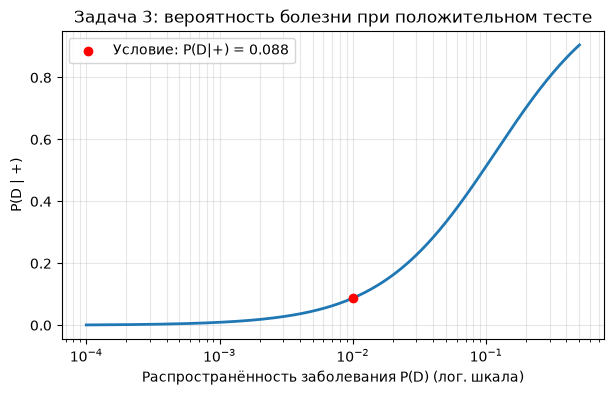

In [12]:
# Зависимость P(D|+) от распространённости заболевания
prev = np.logspace(-4, -0.3, 300)
ppv = prev * sens / (prev * sens + (1 - prev) * (1 - spec))

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(prev, ppv, lw=2)
ax.scatter([p_D], [p_D_given_pos], color="red", zorder=3, label=f"Условие: P(D|+) = {p_D_given_pos:.3f}")
ax.set_xlabel("Распространённость заболевания P(D) (лог. шкала)")
ax.set_ylabel("P(D | +)")
ax.set_title("Задача 3: вероятность болезни при положительном тесте")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.show()

**Ответ к задаче 3.** $P(D \mid +) \approx 0.0876$, т.е. лишь ≈8.8% людей с положительным тестом действительно больны.

Причина — низкая априорная вероятность (1%): здоровых в 99 раз больше, и даже 10% ложноположительных среди них (≈990 на 10 000) многократно превышает число истинно положительных (≈95). Это классический пример «ошибки игнорирования базовой частоты». При росте распространённости заболевания $P(D \mid +)$ быстро растёт.

Повторный положительный тест поднимает вероятность до ≈0.477 — **при условии**, что результаты тестов условно независимы при фиксированном статусе заболевания и оба теста имеют те же чувствительность и специфичность:
$P(D \mid +,+) = \dfrac{0.01 \cdot 0.95^2}{0.01 \cdot 0.95^2 + 0.99 \cdot 0.10^2} \approx 0.4769$. При зависимых результатах это число из исходных данных не следует.

## Задача 4. «Студенты и предметы»

**Дано:** гипотезы — студент посещает курс Алгебры ($Al$) или Анализа ($An$); $E$ — студент сдал экзамен.
- $P(Al) = 0.7$, $P(An) = 0.3$;
- $P(E \mid Al) = 0.8$, $P(E \mid An) = 0.7$.

*Допущение:* считаем, что каждый студент относится ровно к одной из двух групп (Алгебра или Анализ), а фраза
«студенты изучают оба предмета» — неточность условия. Само по себе то, что доли 70% и 30% в сумме дают 100%,
несовместность не доказывает (возможны студенты на обоих курсах и ни на одном). При принятом допущении
гипотезы образуют полную группу несовместных событий и формула полной вероятности применима; если группы
пересекаются, исходных данных для расчёта недостаточно.

**Решение.** Полная вероятность сдачи экзамена:

$$P(E) = 0.7 \cdot 0.8 + 0.3 \cdot 0.7 = 0.56 + 0.21 = 0.77.$$

По формуле Байеса:

$$P(Al \mid E) = \frac{0.56}{0.77} \approx 0.7273.$$

In [13]:
priors4 = [0.7, 0.3]
lik4 = [0.8, 0.7]

p_E = total_probability(priors4, lik4)
post4 = bayes(priors4, lik4)

display(pd.DataFrame({
    "Априорная P(курс)": priors4,
    "P(E | курс)": lik4,
    "P(курс ∩ E)": np.array(priors4) * np.array(lik4),
    "Апостериорная P(курс | E)": post4,
}, index=["Алгебра", "Анализ"]))
print(f"P(E) = {p_E:.4f}")
print(f"P(Алгебра | сдал) = {post4[0]:.4f}  ({post4[0]:.2%})")

,Априорная P(курс),P(E | курс),P(курс ∩ E),Апостериорная P(курс | E)
Алгебра,0.7000,0.8000,0.5600,0.7273
Анализ,0.3000,0.7000,0.2100,0.2727


P(E) = 0.7700
P(Алгебра | сдал) = 0.7273  (72.73%)


In [14]:
# Проверка Монте-Карло
is_algebra = rng.random(N) < priors4[0]
passed = rng.random(N) < np.where(is_algebra, lik4[0], lik4[1])
print(f"P(E)              ≈ {passed.mean():.4f}  (аналитически {p_E:.4f})")
print(f"P(Алгебра | сдал) ≈ {is_algebra[passed].mean():.4f}  (аналитически {post4[0]:.4f})")

P(E)              ≈ 0.7699  (аналитически 0.7700)
P(Алгебра | сдал) ≈ 0.7276  (аналитически 0.7273)


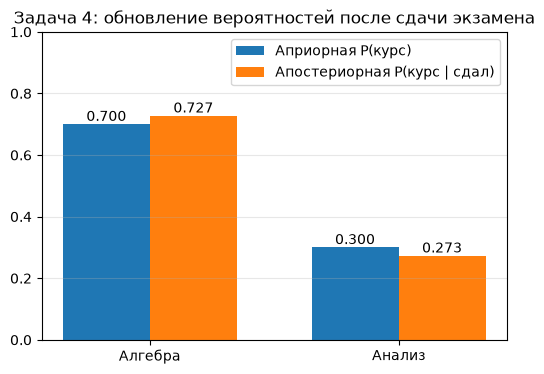

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(2)
w = 0.35
b1 = ax.bar(x - w / 2, priors4, w, label="Априорная P(курс)")
b2 = ax.bar(x + w / 2, post4, w, label="Апостериорная P(курс | сдал)")
ax.bar_label(b1, fmt="%.3f")
ax.bar_label(b2, fmt="%.3f")
ax.set_xticks(x, ["Алгебра", "Анализ"])
ax.set_ylim(0, 1)
ax.set_title("Задача 4: обновление вероятностей после сдачи экзамена")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.show()

**Ответ к задаче 4.** При допущении, что группы не пересекаются, $P(\text{Алгебра} \mid \text{сдал}) = 0.56 / 0.77 \approx 0.727$ (72.7%).

Апостериорная вероятность лишь немного выше априорной (0.7 → 0.727), поскольку вероятности сдачи на двух курсах близки (0.8 и 0.7): факт сдачи экзамена слабо различает гипотезы.

## Выводы

1. **Правило умножения и формула полной вероятности** позволяют находить вероятность многоэтапных событий. В задаче 1 итоговая вероятность успеха 0.54 — это взвешенное среднее условных вероятностей по тропам; выбор тропы B повышает шанс с 0.3 до 0.7.
2. **Цепочки зависимых событий** (задача 2): вероятность пройти все этапы — произведение условных вероятностей, $P(A)\,P(B \mid A)\,P(C \mid A \cap B)$. При допущении, что C условно независимо от A при известном B, получаем $0.6 \cdot 0.4 \cdot 0.7 = 0.168$; без этого допущения данных для однозначного ответа недостаточно. Каждый успешный этап повышает шансы на следующем, а провал любого замка делает получение сокровища невозможным.
3. **Формула Байеса** «переворачивает» условную вероятность: от $P(\text{данные} \mid \text{гипотеза})$ к $P(\text{гипотеза} \mid \text{данные})$. Апостериорная вероятность определяется одновременно правдоподобием и априорной вероятностью.
4. **Роль априорной вероятности** (задача 3): даже при точном тесте (95% / 90%) редкость болезни (1%) приводит к тому, что положительный результат означает болезнь лишь с вероятностью ≈8.8%. Игнорирование базовой частоты — частая ошибка; на практике для подтверждения диагноза используют повторные тесты. Если результаты тестов условно независимы при фиксированном статусе заболевания и имеют те же характеристики, после второго положительного теста вероятность болезни ≈47.7%; при зависимых тестах это число не следует из исходных данных.
5. **Информативность наблюдения** (задача 4, при допущении, что группы студентов не пересекаются): если правдоподобия при разных гипотезах близки (0.8 и 0.7), наблюдение слабо меняет вероятности (0.7 → 0.727). Чем сильнее различаются $P(\text{данные} \mid H_i)$, тем больше сдвиг апостериорной вероятности.
6. Все аналитические результаты подтверждены моделированием Монте-Карло на $10^6$ испытаниях — расхождения в пределах статистической погрешности (~$10^{-3}$).